In [1]:
%load_ext autoreload
%autoreload 2

In [168]:
# -*- coding: utf-8 -*-
import os
import warnings

import graphviz
import torch
import torch.nn as nn
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# from config import Config
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from torch import nn
from xgboost import XGBClassifier

from src.custom_models.myMLP import MyModel
from src.feature.feature_selection import FeatureTransformer

In [14]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*(parseString|resetCache|parseAll).*",
)

import logging

os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"


logging.getLogger("mlflow").setLevel(logging.ERROR)

In [3]:

from config import Config
from src.core_funcs import (
    run_experiment,
    run_shap,
    setup_validation,
)
from src.custom_models.meta_model import MyStackingRidge
from src.custom_models.myMLP import CheckpointManager, EarlyStopping, MyModel
from src.feature.features import (
    DNN_encoder,
    FeatureTransformer,
    encoder_transformer,
)
from src.modeling.predict import Predictor
from src.utils.model_saving import ModelSaver
from src.utils.mymlflow import Mlflow_logger

In [4]:
X_train, X_holdout, y_train, y_holdout = setup_validation(Config.path_train_data, test_size = 0.2)

In [5]:
#cmd - python -m mlflow server --port 5000
logger = Mlflow_logger("Titanic_kaggle")
logger.setup_connection()

Start tracking experiments at http://127.0.0.1:5000


## Baseline

In [228]:
logreg_pipeline = {"logreg": {
            "pipeline": Pipeline([
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", LogisticRegression()),
                ]),
            "parameters": {
                "feature_transform__m": [4],
                "model__C": [1.053579],  # [np.float64(1.053578947368421)], #np.linspace(0.001,20,20),
                "model__penalty": ["elasticnet"],  # ['l2','l1','elasticnet'],
                "model__solver": ["saga"],
                "model__max_iter": [2000],
                "model__l1_ratio": [0.7],  # [0.1, 0.3, 0.5, 0.7, 0.9],
                "model__random_state": [Config.seed],
                "model__n_jobs": [-1],},
            "search_type": "grid",
            "fit_param": {},
            "n_iter": 1,
            "plot_param": "model__l1_ratio",
            "heatmap_params": ("model__l1_ratio", "model__max_iter"),
            "shap_mode":"linear",
            "cv": 5,
            "n_jobs":-1}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.8370786516853933, best mean val accuracy 0.837092484979809, best_val_std 0.014871244740204894
Best searched params
feature_transform__m           4
model__C                1.053579
model__l1_ratio              0.7
model__max_iter             2000
model__n_jobs                 -1
model__penalty        elasticnet
model__random_state           42
model__solver               saga


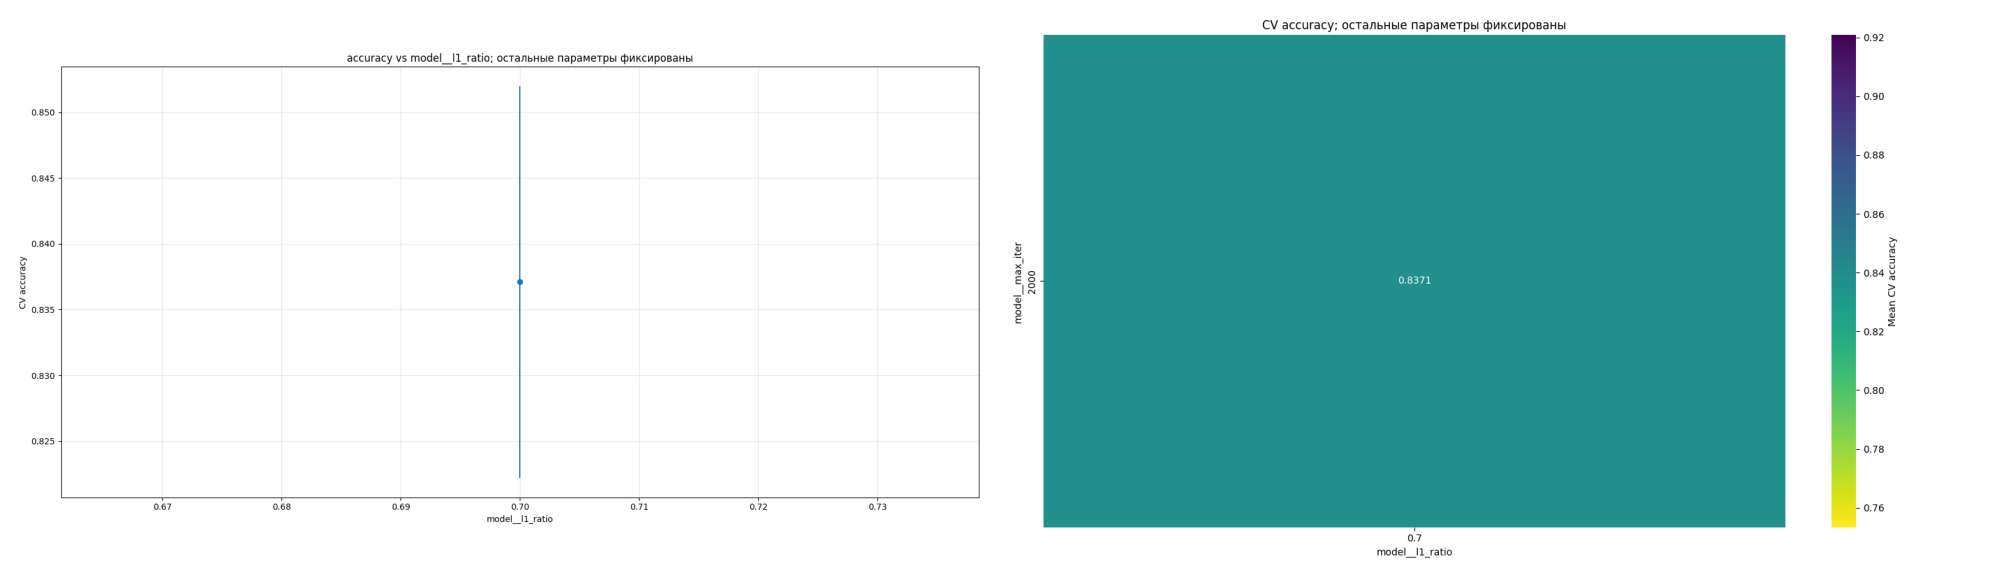

In [229]:
logreg_results = run_experiment(
    X_train, y_train,
    "logreg",
    logreg_pipeline,
    logger
)
ModelSaver.save_ensemble(logreg_results['best_ensemble'],"logreg")

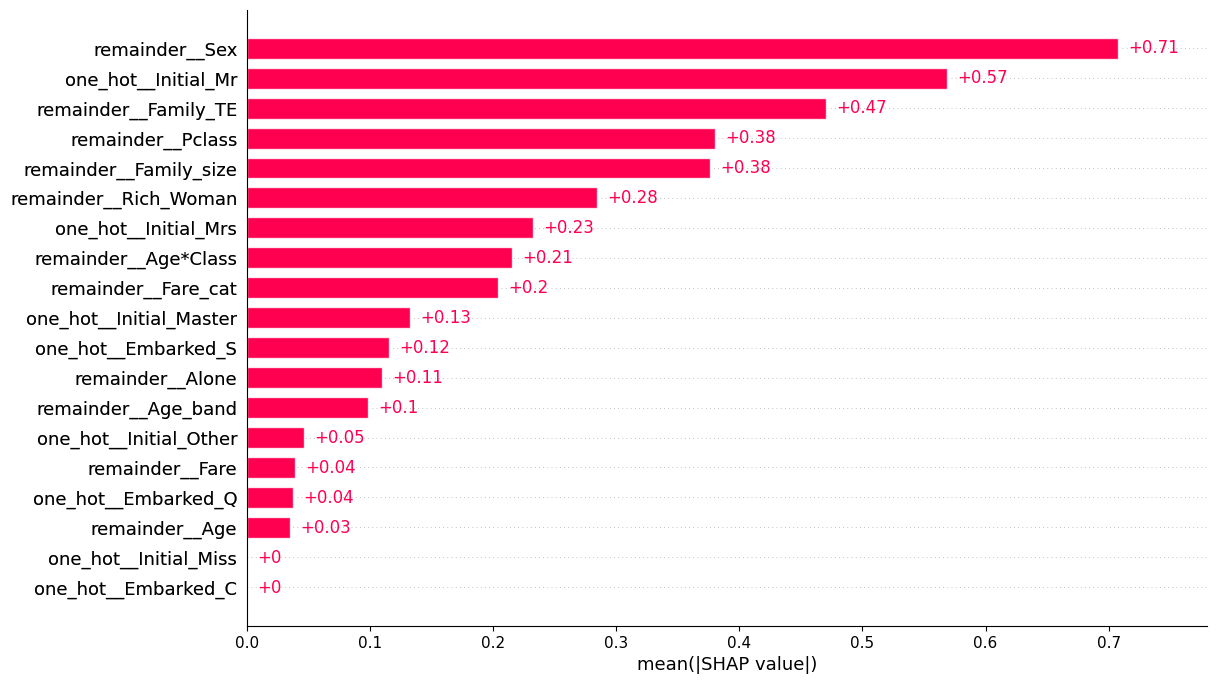

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString

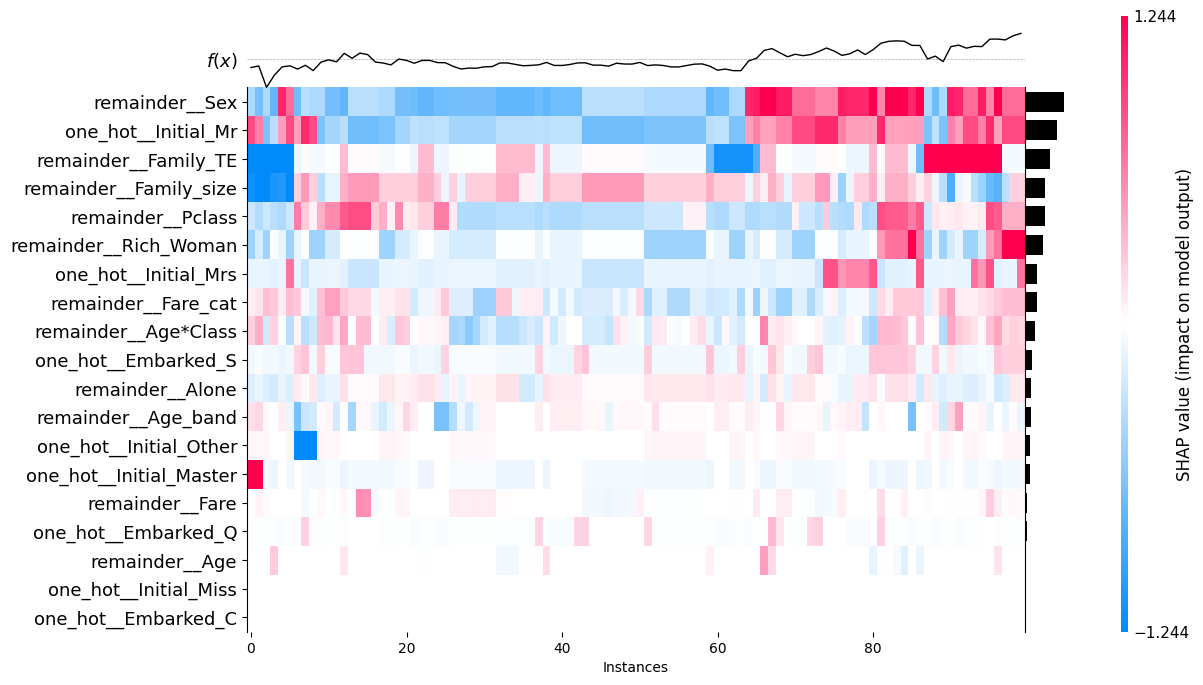

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


In [230]:
logreg_shap = run_shap(
    X_train,
    logreg_results,
    mode="linear",
    logger = logger
)

Самая большая важность у признаков связанных с возрастом и полом, что в целом логично и подтверждает основую теорию что женщин и детей спасают первыми и их шанс выживани заметно выше. Так же общий процент выживания семьи так же имеет хороший вес, что так же может говорить о важности гипотезы, что семьи выживают или умирают вместе

## KNN

In [155]:
knn_pipeline = {"knn": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier()),
        ]),
    "parameters": {
            "model__n_neighbors": [6,7,8],
            "model__weights": ["distance"],
            "model__p": [1],
            "model__n_jobs": [-1],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 1,
    "plot_param": "model__n_neighbors",
    "heatmap_params": ("model__n_neighbors", "model__p"),
    "shap_mode": "dnn",
    "cv": 5,
    "n_jobs": -1,
}}

Начинаем обучение 3 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.7991573033707865, best mean val accuracy 0.7992022062444597, best_val_std 0.01810935126535334
Best searched params
model__n_jobs             -1
model__n_neighbors         7
model__p                   1
model__weights      distance


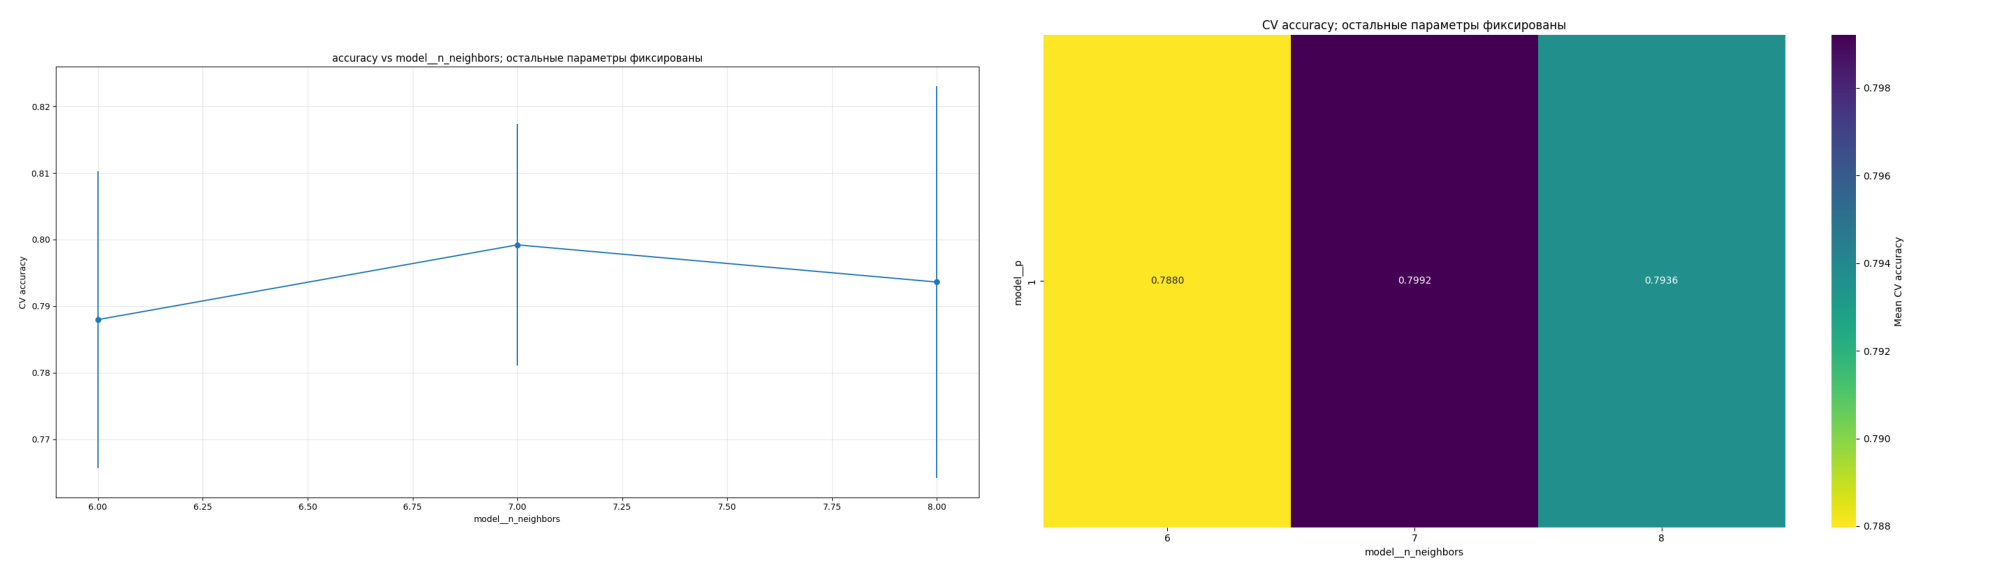

In [156]:
knn_results = run_experiment(
    X_train, y_train,
    "knn",
    knn_pipeline,
    logger
)

## DecisionTree

In [233]:
decision_tree_pipeline = {"decision_tree": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", DecisionTreeClassifier()),
        ]),
    "parameters": {
        "feature_transform__m": [2],
        "model__max_depth": [8],
        "model__criterion": ["gini"],
        "model__splitter": ["best"],
        "model__min_samples_split": [50],
        "model__min_samples_leaf": [20],
        "model__max_leaf_nodes": [15],  # Лушчее пока 9
        "model__min_impurity_decrease": [0],
        "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__max_depth",
    "heatmap_params": ("model__max_depth", "model__min_samples_leaf"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.8117977528089888, best mean val accuracy 0.811878262582488, best_val_std 0.027308432087967544
Best searched params
feature_transform__m             2
model__criterion              gini
model__max_depth                 8
model__max_leaf_nodes           15
model__min_impurity_decrease     0
model__min_samples_leaf         20
model__min_samples_split        50
model__random_state             42
model__splitter               best


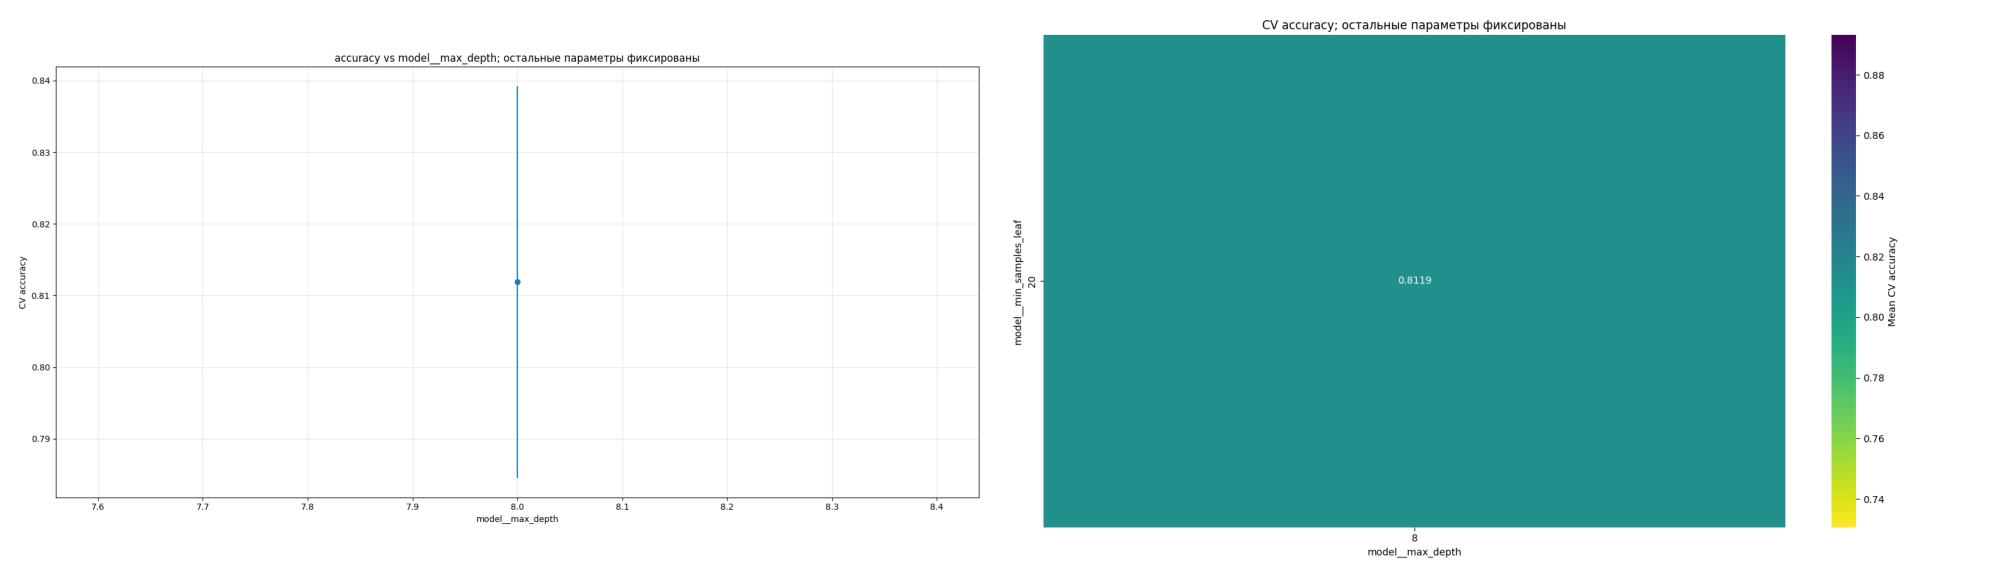

In [234]:
decision_tree_results = run_experiment(
    X_train, y_train,
    "decision_tree",
    decision_tree_pipeline,
    logger
)
ModelSaver.save_ensemble(decision_tree_results['best_ensemble'],"decision_tree")

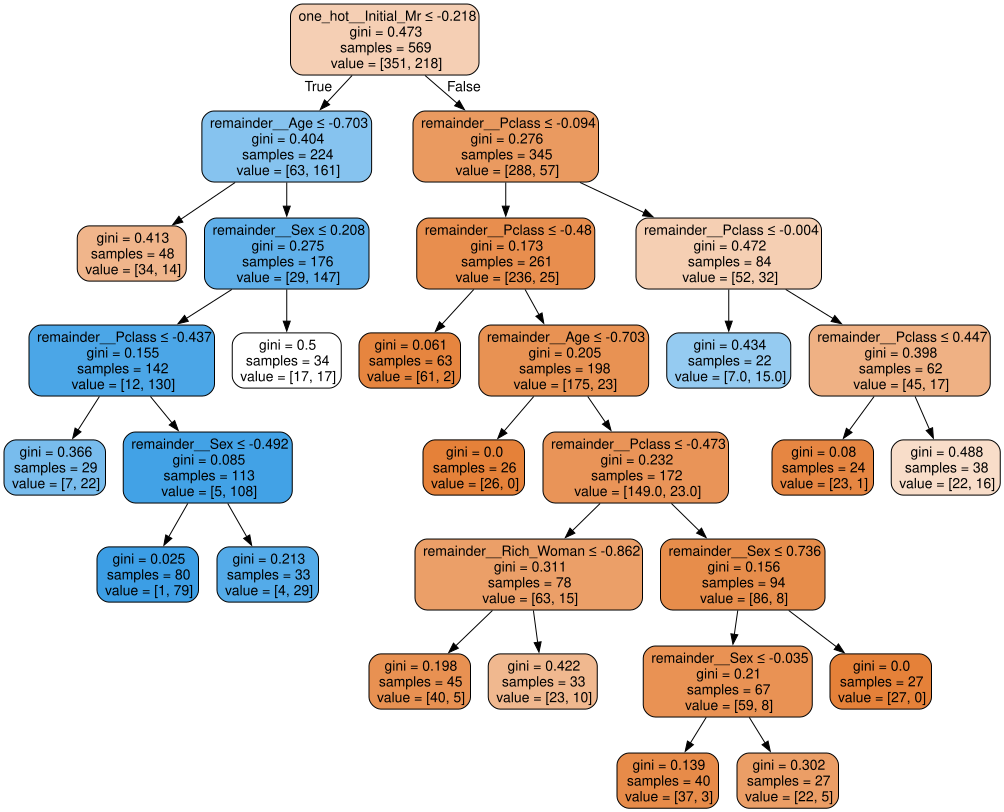

In [235]:
dot_data = export_graphviz(
    decision_tree_results['best_ensemble'][0]['model'],
    out_file=None,
    filled=True,
    rounded=True,
    special_characters=True,
    feature_names=decision_tree_results['best_results']['best_cols'],
)
graph = graphviz.Source(dot_data)
graph

## RandomForest

In [236]:
random_forest_pipeline = {"random_forest": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", RandomForestClassifier()),
        ]),
    "parameters": {
            # bootstrap=True
                "feature_transform__m": [1],
                "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int),
                "model__max_depth": [6],  # np.linspace(1, 10, 5, dtype=int),
                "model__criterion": ["gini"],
                "model__n_jobs": [-1],
                "model__min_samples_split": [15],  # np.linspace(10, 100, 5, dtype=int),
                "model__min_samples_leaf": [15],  # np.linspace(5, 15, 5, dtype=int), #'min_samples_leaf': np.int64(6)
                "model__max_leaf_nodes": [12],  # [5,7,9,11],
                "model__min_impurity_decrease": [0],  # [0],
                "model__max_features": [None],
                "model__bootstrap": [True],
                "model__max_samples": [0.8],
                "model__oob_score": [True],
                "model__random_state": [Config.seed],
            },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__max_depth",
    "heatmap_params": ("model__max_leaf_nodes", "model__max_depth"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.8356741573033708, best mean val accuracy 0.8357037328868315, best_val_std 0.019836618896372088
Best searched params
feature_transform__m             1
model__bootstrap              True
model__criterion              gini
model__max_depth                 6
model__max_features           None
model__max_leaf_nodes           12
model__max_samples             0.8
model__min_impurity_decrease     0
model__min_samples_leaf         15
model__min_samples_split        15
model__n_estimators           1000
model__n_jobs                   -1
model__oob_score              True
model__random_state             42


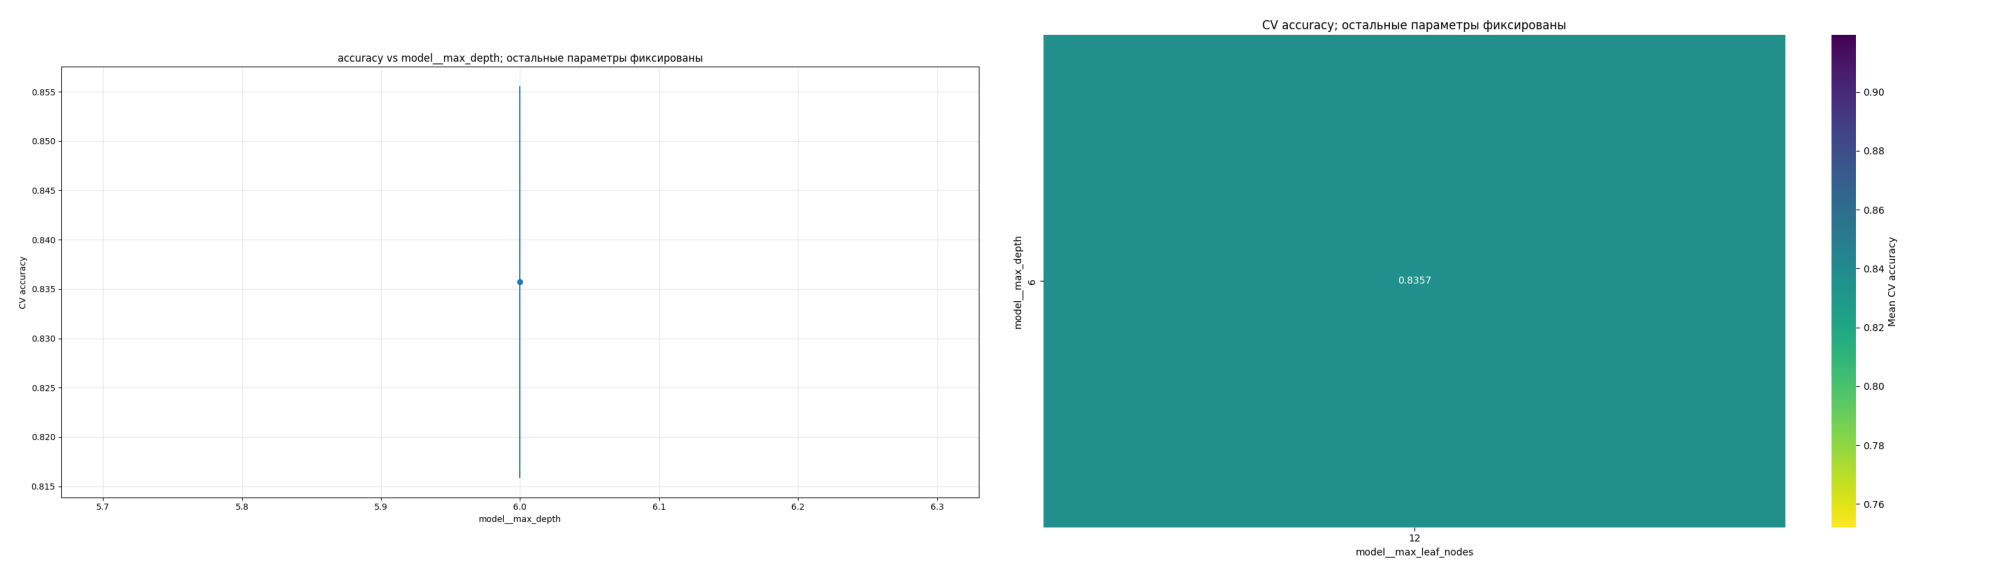

In [237]:
random_forest_results = run_experiment(
    X_train, y_train,
    "random_forest",
    random_forest_pipeline,
    logger
)
ModelSaver.save_ensemble(random_forest_results['best_ensemble'],"random_forest")

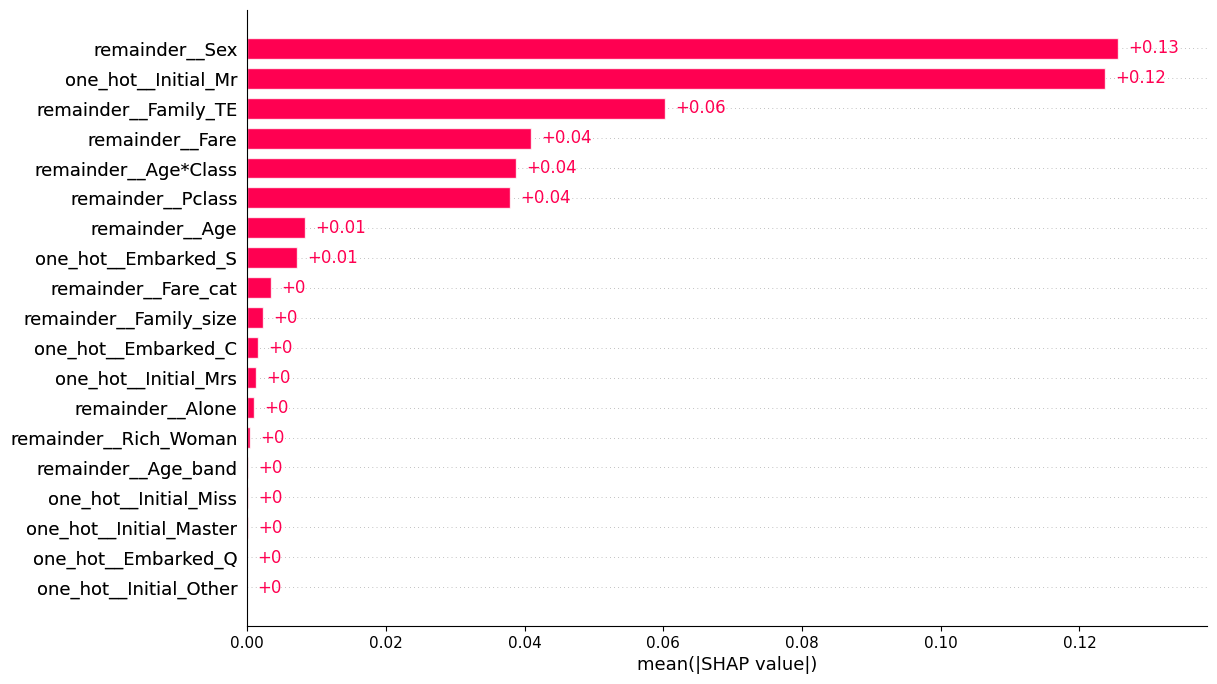

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString

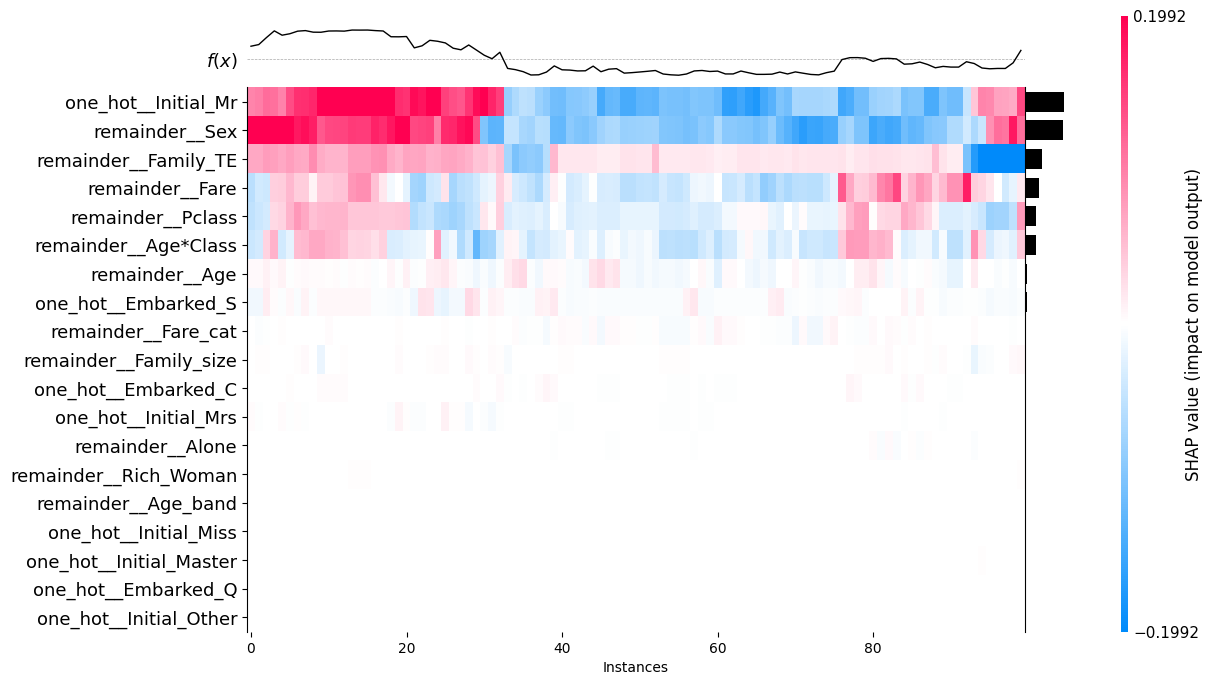

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


In [190]:
random_forest_shap = run_shap(
    X_train,
    random_forest_results,
    mode="random_forest",
    logger = logger
)

## DNN

In [238]:
dnn_pipeline = {"dnn": {
                "pipeline": Pipeline([
                    ("feature_transform", FeatureTransformer(cat_boosting=True)),
                    ("encoder", DNN_encoder()),
                    ("model", MyModel()),
                ]),

                "parameters": {
                    # Данные
                    "model__cat_cols": [FeatureTransformer.X_cat_cols],
                    "model__num_cols": [FeatureTransformer.X_num_cols],
                    # Обучение
                    "model__epochs": [1000],
                    "model__device": [Config.device],
                    # Архитектура
                    "model__emb_dim": [24],
                    "model__inner_n": [256],
                    "model__drop_n": [0.1],
                    "model__n_layers": [2],
                    "model__use_batchnorm": [True],
                    # Loss
                    "model__loss_cls": [nn.CrossEntropyLoss],
                    #Regularization
                    "model__l1_lambda":[0.001],
                    # Optimizer
                    "model__optim": [torch.optim.Adam],
                    "model__optim_lr": [0.005],
                    # Scheduler
                    "model__scheduler": [
                        torch.optim.lr_scheduler.ReduceLROnPlateau
                    ],
                    "model__lr_scheduler": [True],
                    "model__factor": [0.006],
                    "model__patience": [15],
                    "model__threshold": [0.05],
                    "model__min_lr": [1e-15],
                    # Early Stopping
                    "model__early_stopping_patience": [25],
                    "model__early_stopping_threshold": [0.001],
                    # DataLoader
                    "model__batch_size": [512],
                    # Checkpoint
                    "model__saving_threshold": [0.001],
                    "model__save_path": ["checkpoints"],
                },
                "search_type": "grid",
                "fit_param": {"model__callbacks":[CheckpointManager(),EarlyStopping()]}, #,MLflow_logger()
                "n_iter": 1, #для рандом серча
                "plot_param": "model__optim_lr",
                "heatmap_params": ("model__optim_lr", "model__n_layers"),
                "shap_mode": "dnn",
                "cv": 5,
                "n_jobs": 1,
        }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

РћР±СѓС‡РµРЅРёРµ РѕСЃС‚Р°РЅРѕРІР»РµРЅРѕ РЅР° СЌРїРѕС…Рµ 94


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

РћР±СѓС‡РµРЅРёРµ РѕСЃС‚Р°РЅРѕРІР»РµРЅРѕ РЅР° СЌРїРѕС…Рµ 93


... (3 outputs left out)

РћР±СѓС‡РµРЅРёРµ РѕСЃС‚Р°РЅРѕРІР»РµРЅРѕ РЅР° СЌРїРѕС…Рµ 74


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

РћР±СѓС‡РµРЅРёРµ РѕСЃС‚Р°РЅРѕРІР»РµРЅРѕ РЅР° СЌРїРѕС…Рµ 85
Best OOF 0.8300561797752809, best mean val accuracy 0.83006993006993, best_val_std 0.016739056454286985
Best searched params
model__batch_size                                                                 512
model__device                                                                    cuda
model__drop_n                                                                     0.1
model__early_stopping_patience                                                     25
model__early_stopping_threshold                                                 0.001
model__emb_dim                                                                     24
model__epochs                                                                    1000
model__factor                                                                   0.006
model__inner_n                                                                    256
model__l1_lambda                          

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString

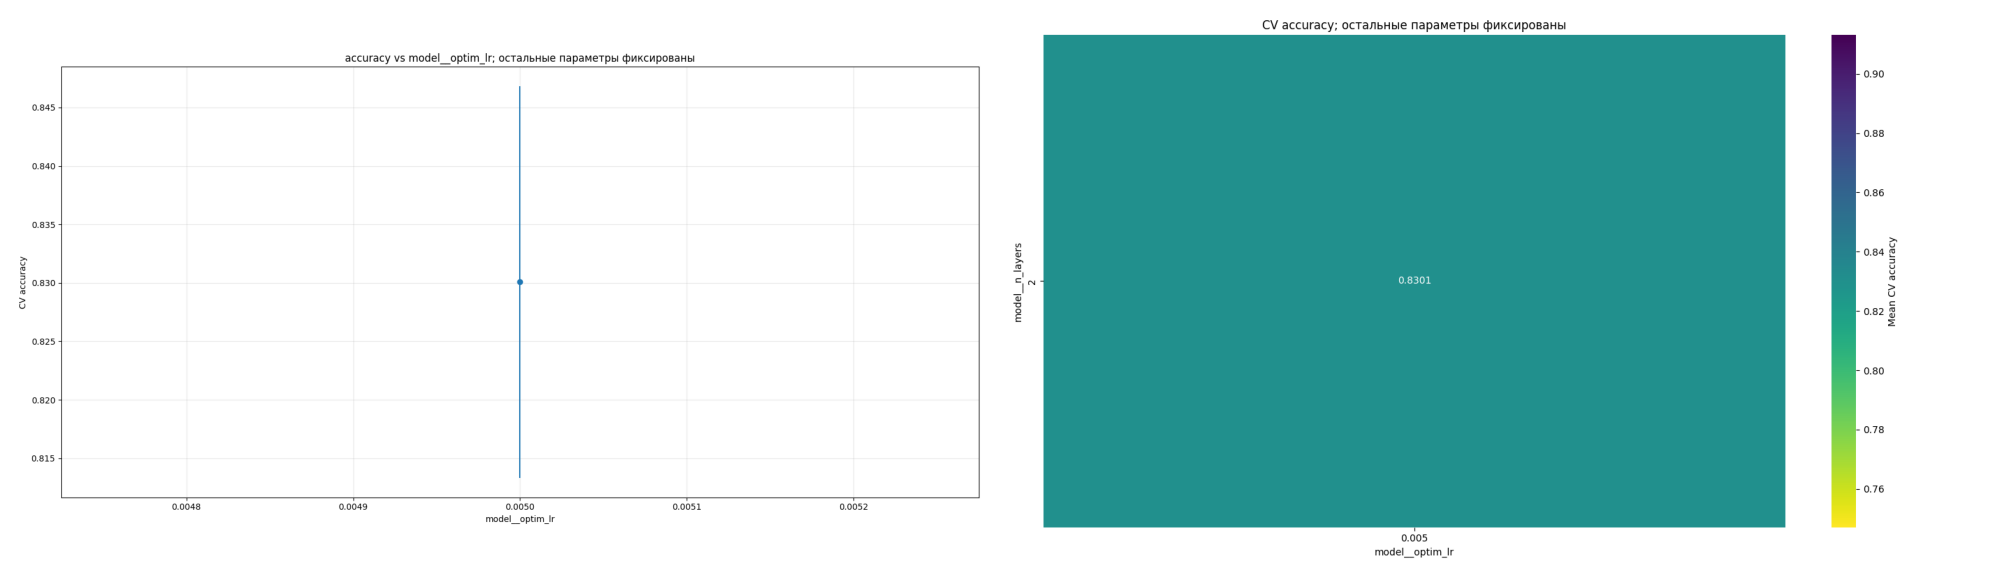

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString

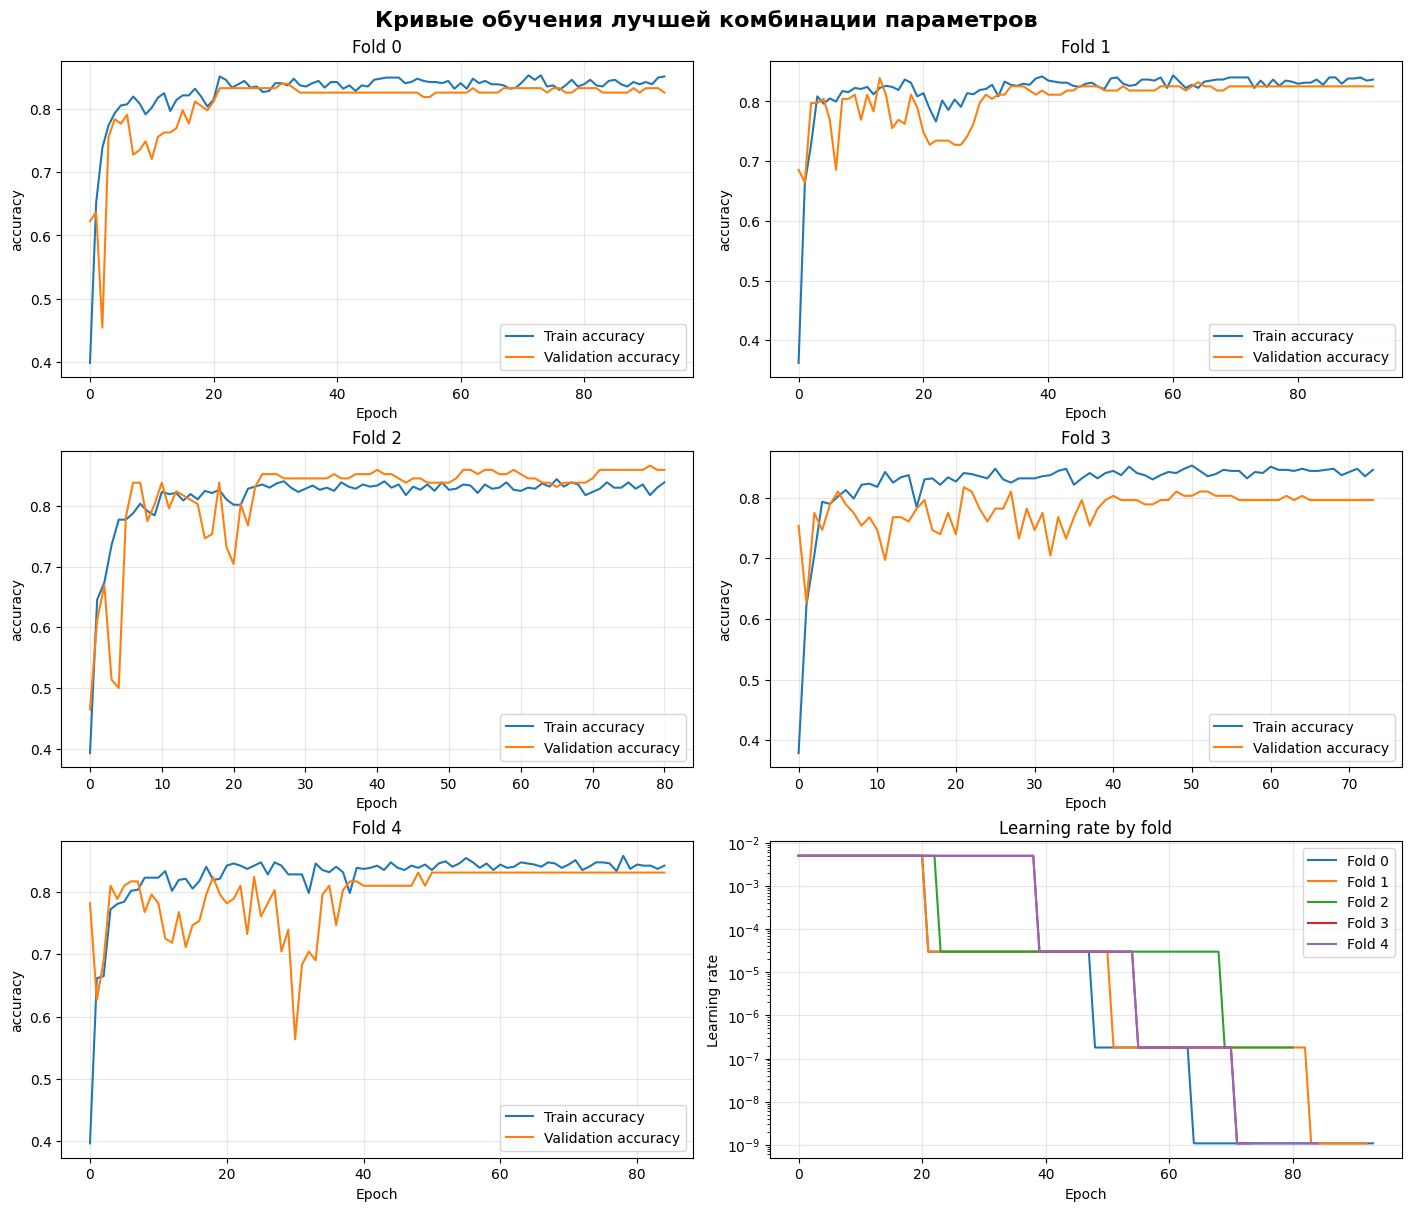

In [239]:
dnn_results = run_experiment(
    X_train, y_train,
    "dnn",
    dnn_pipeline,
    logger
)
ModelSaver.save_ensemble(dnn_results['best_ensemble'],"dnn")

При тренировке постарался чтобы скор на валидации не скакал и сходилсчя максимально ровненько, так же чтобы lr scheduler понизил скорость обучения до остановки еарли стоппингом

PermutationExplainer explainer: 144it [00:11,  1.60it/s]                         
PermutationExplainer explainer: 144it [00:10,  2.07s/it]                         


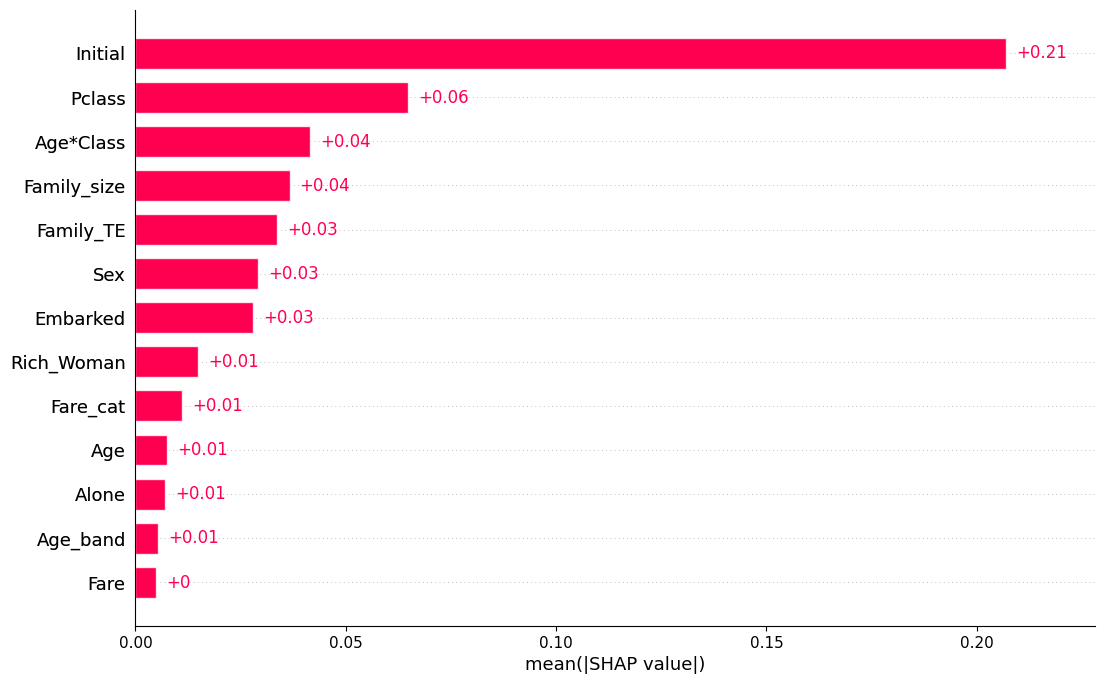

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString

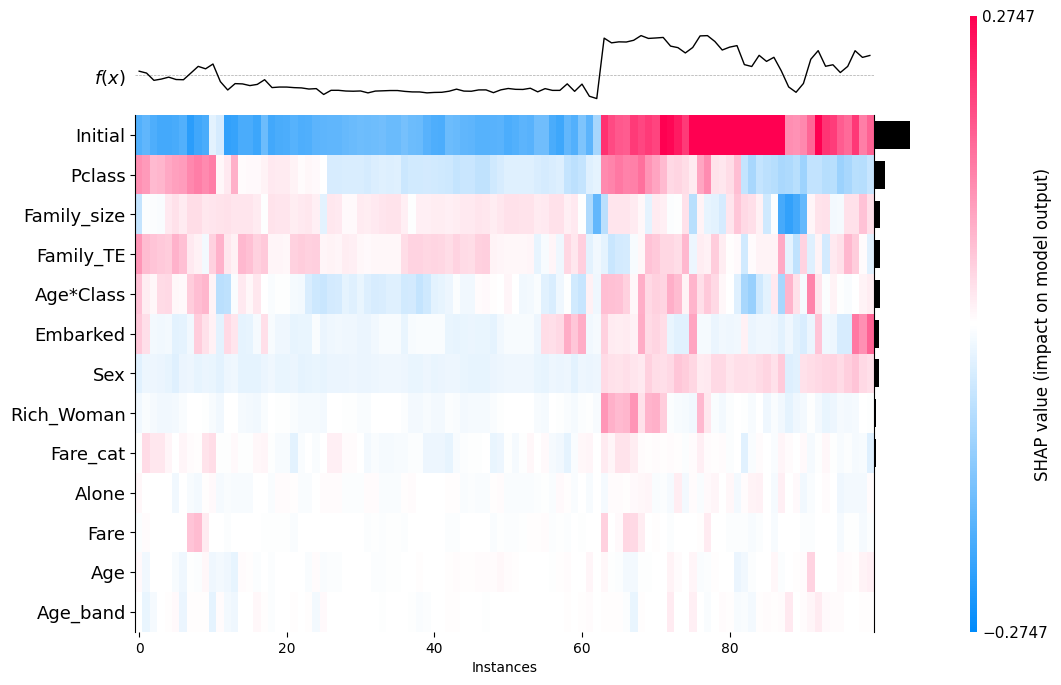

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


In [240]:
dnn_optuna_shap = run_shap(
    X_train,
    dnn_results,
    mode="dnn",
    logger = logger
)

Нейронная сеть с слоем эмбедингов оч большое предпочтение отдала инициалам, видимо из за того что они оптимально кодируют возраст и статус, что может быть весомой информацией при предсказании класса.

## Catboost

In [241]:
catboost_pipeline = {"catboost": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", CatBoostClassifier(allow_writing_files=False)),
        ]),
        "parameters": {
            "model__boosting_type": ["Plain"],  # ['Plain', 'Ordered'],
            "model__iterations": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.547368],  # np.linspace(0.01,0.1,5, dtype=float),
            "model__depth": [5],  # [4, 5, 6, 8]
            "model__bootstrap_type": ["Bayesian"],
            "model__thread_count": [-1],
            "model__rsm": [1.0],  # [0.6, 0.8, 1.0],
            "model__l2_leaf_reg": [3.164737],  #  3.164737,
            "model__eval_metric": ["Accuracy"],
            "model__border_count": [32],
            "model__loss_function": ["Logloss"],
            "model__random_seed": [Config.seed],
            "model__bagging_temperature": [1],  # [0, 0.5, 1, 2],
            "model__random_strength": [0.5],  # [0, 0.5, 1, 2],
            "model__verbose": [False],
            'model__early_stopping_rounds':[25]
        },
        'fit_param': {"model__cat_features": FeatureTransformer.X_cat_cols},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
        "shap_mode": "catboost",
        "cv": 5,
        "n_jobs": - 1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.8525280898876404, best mean val accuracy 0.852555894809416, best_val_std 0.01575417909524321
Best searched params
model__bagging_temperature           1
model__boosting_type             Plain
model__bootstrap_type         Bayesian
model__border_count                 32
model__depth                         5
model__early_stopping_rounds        25
model__eval_metric            Accuracy
model__iterations                 1000
model__l2_leaf_reg            3.164737
model__learning_rate          0.547368
model__loss_function           Logloss
model__random_seed                  42
model__random_strength             0.5
model__rsm                         1.0
model__thread_count                 -1
model__verbose                   False


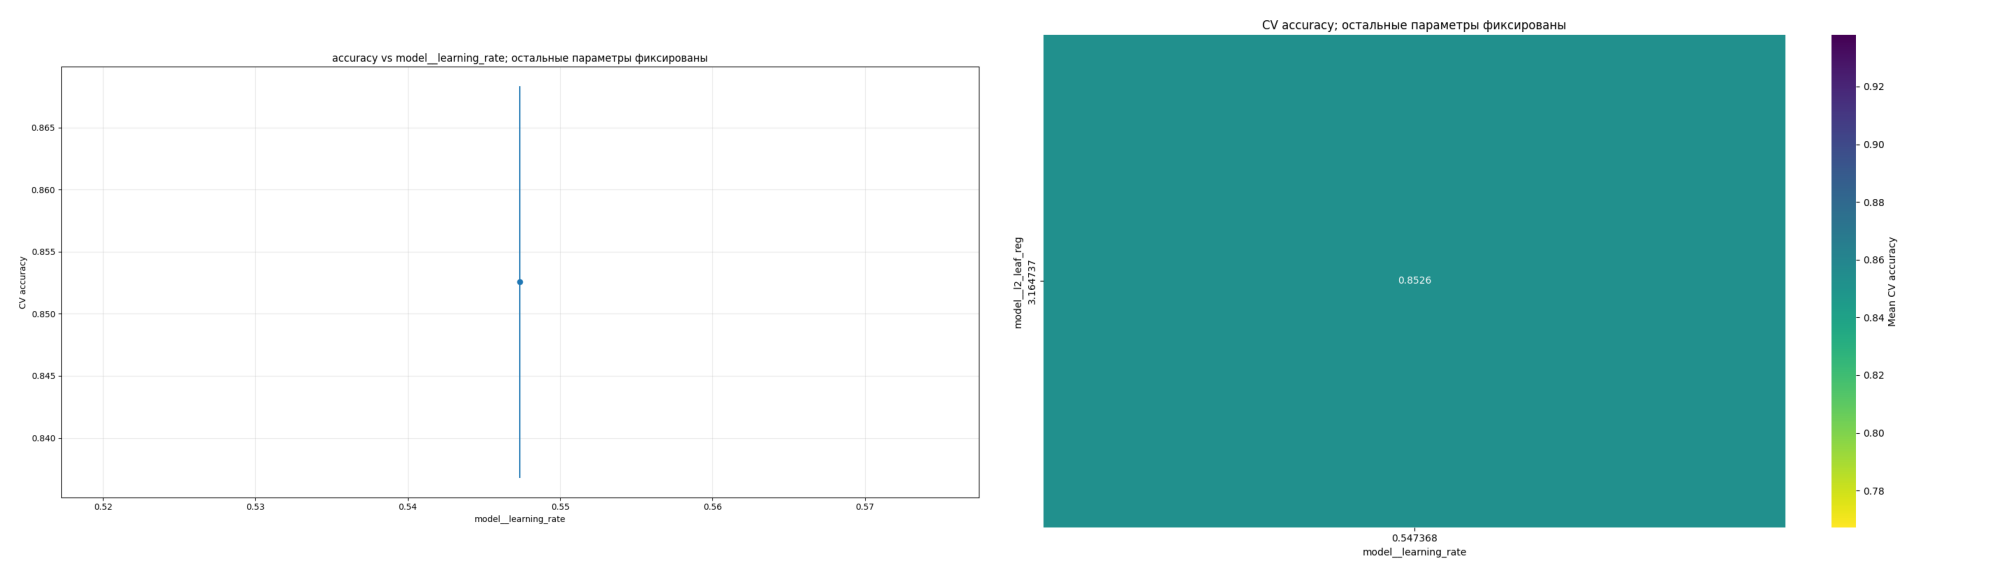

In [242]:
catboost_results = run_experiment(
    X_train, y_train,
    "catboost",
    catboost_pipeline,
    logger
)
ModelSaver.save_ensemble(catboost_results['best_ensemble'],"catboost")

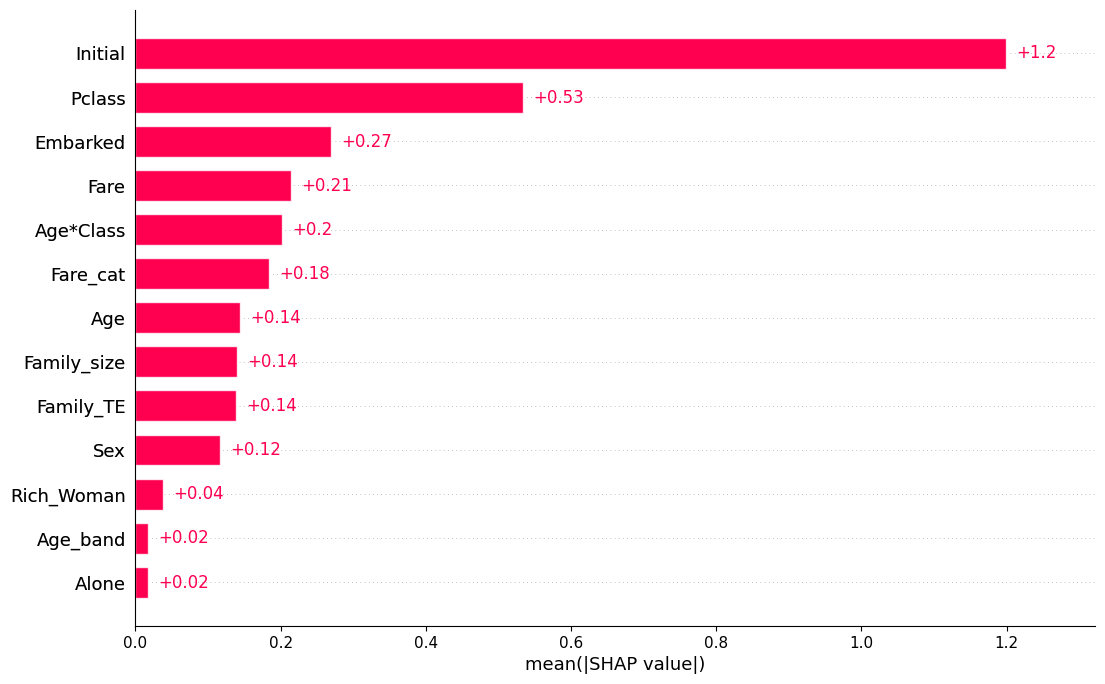

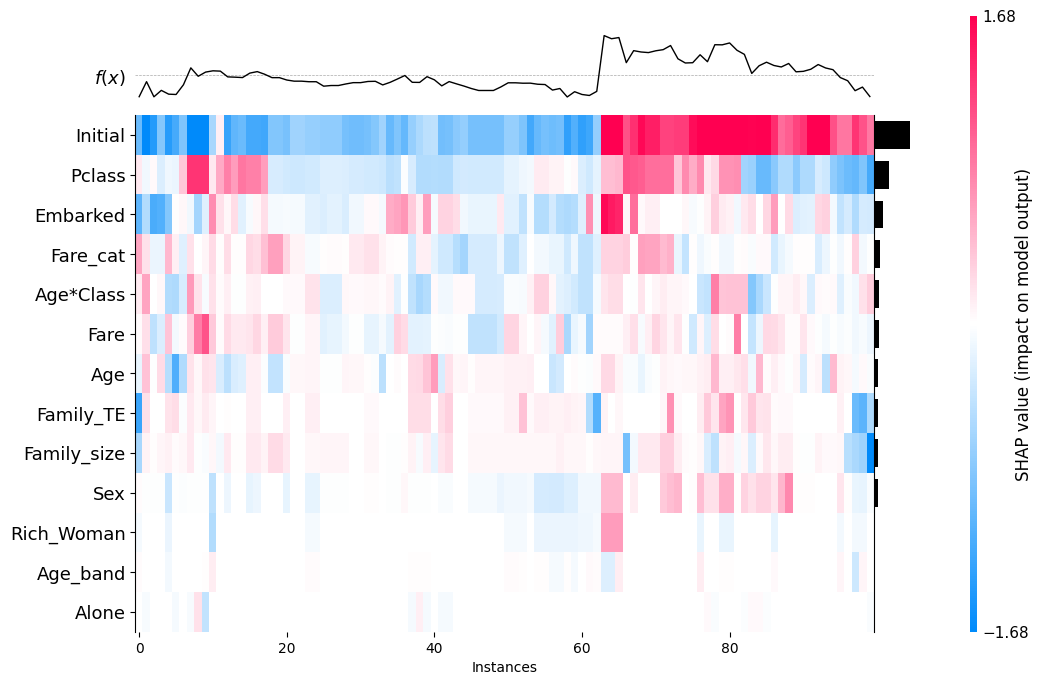

In [126]:
catboost_shap = run_shap(
    X_train,
    catboost_results,
    mode="catboost",
    logger = logger
)

Catboost так же отдал инициалам наибольшее предпочтение, видимо он как признак лучше всего кодирует наиболее скорелированную с таргетом информаицю, в целом это логично, он отражает пол и возраст, что весьма полезно. Возможно стоило бы даже их не приводить к единному виду, так как тогда они могли бы еще кодировать и социальный статус, что весьма важно, но если признак rich woman, который кодирует схожую информацию, не имеет большого feature importance это могло бы и не иметь столь большего воздействия на предсказания, и даже наоборот привести к переобучению

## LightGBM

In [243]:
lightgbm_pipeline = {"lightgbm": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", LGBMClassifier()),
        ]),
        "parameters": {
            "feature_transform__m": [1],
            "model__device": ["cpu"],
            "model__boosting_type": ["gbdt"],
            "model__n_estimators": [1000],
            "model__learning_rate": [0.1],
            "model__max_depth": [10],  # [4, 5, 6, 8]
            "model__min_child_weight": [1],  # np.linspace(1,5,3,dtype=int),
            "model__n_jobs": [-1],
            "model__subsample": [0.6],  # [0.6, 0.8, 1.0],
            "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0],
            "model__reg_alpha": [0.1],  # [0.1, 0.2, 0.4, 0.5,1],
            "model__reg_lambda": [10],  # [0.01,0.1,0.5,5,10],
            "model__objective": ["binary"],
            "model__metric": ["binary_error"],
            "model__min_split_gain": [0.01],  # np.linspace(0.01,0.1,5,dtype=float),
            "model__random_state": [Config.seed],
            "model__early_stopping_round":[30]
        },
        "fit_param" : {},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__max_depth"),
        'shap_mode':'lightgbm',
        "cv": 5,
        "n_jobs": 1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 218, number of negative: 351
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000437 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 286
[LightGBM] [Info] Number of data points in the train set: 569, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.383128 -> initscore=-0.476291
[LightGBM] [Info] Start training from score -0.476291
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 30 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

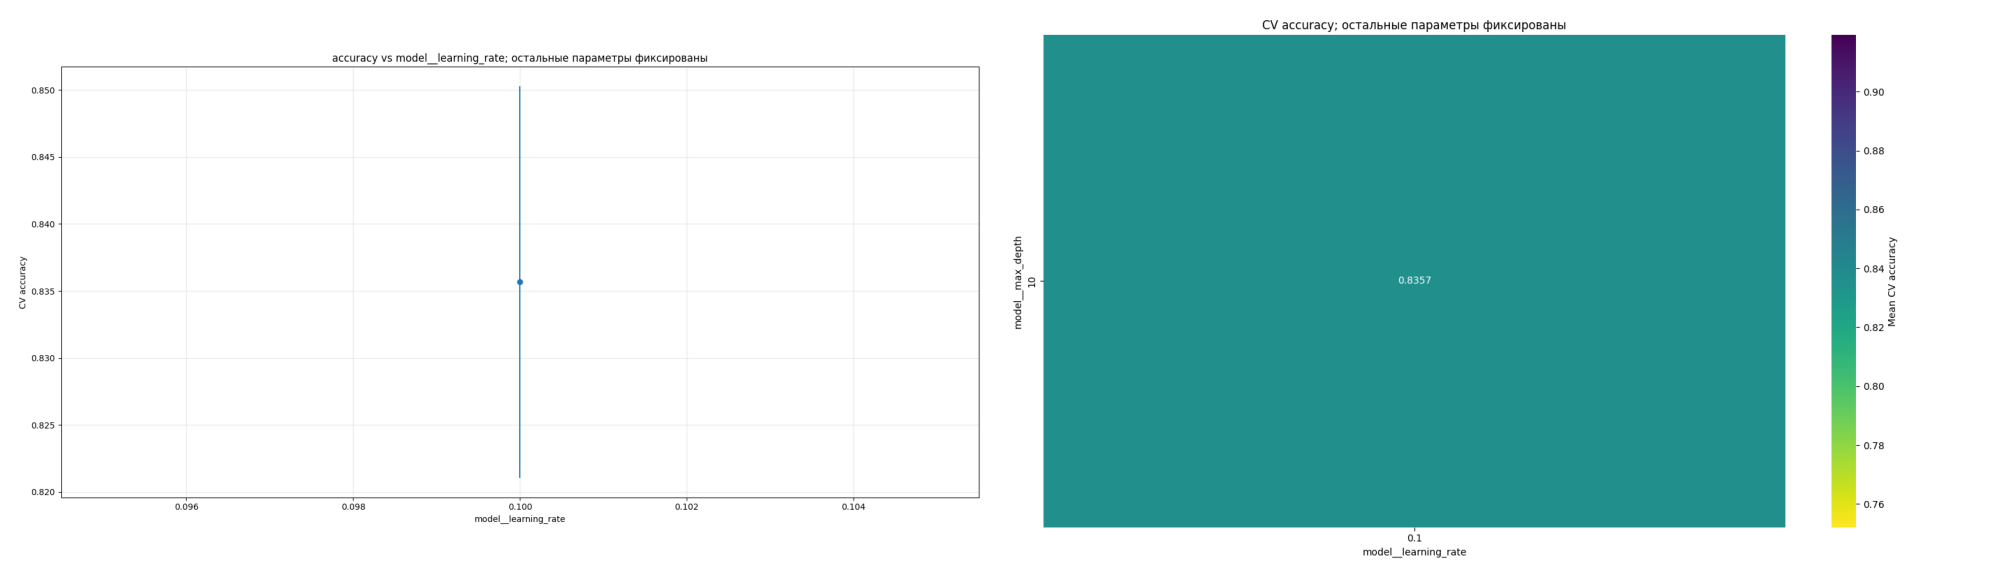

In [244]:
lightgbm_results = run_experiment(
    X_train, y_train,
    "lightgbm",
    lightgbm_pipeline,
    logger
)
ModelSaver.save_ensemble(lightgbm_results['best_ensemble'],"lightgbm")

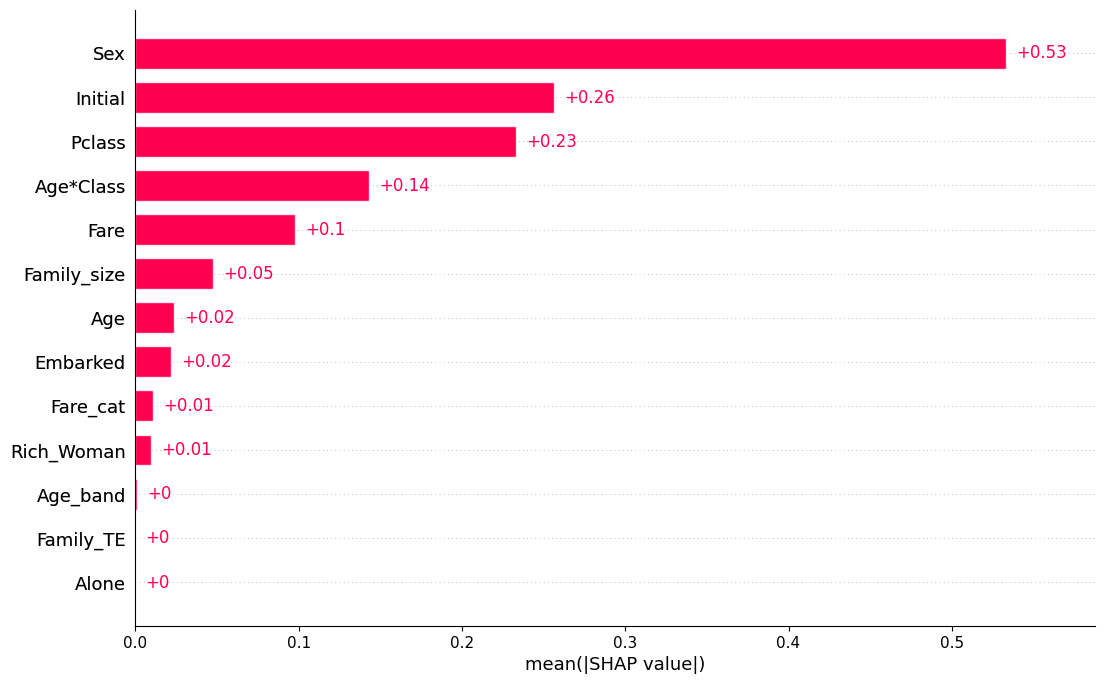

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString

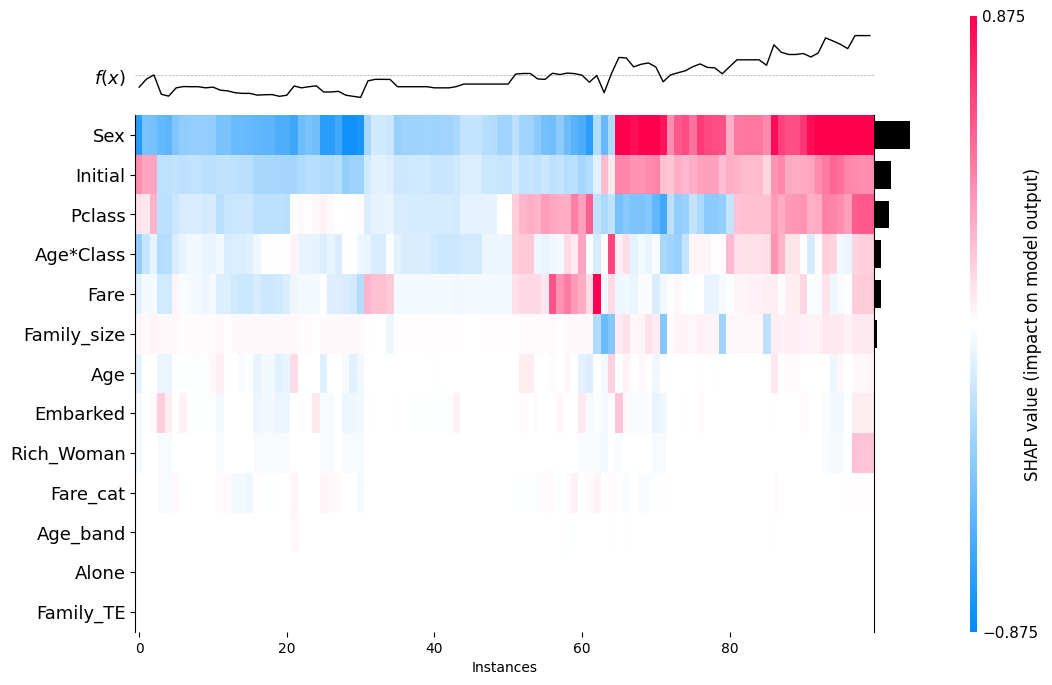

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2170: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2197: DeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\pyparsing\util.py:439: DeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\matplotlib\_mathtext.py:2178: DeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


In [202]:
lightgbm_shap = run_shap(
    X_train,
    lightgbm_results,
    mode="lightgbm",
    logger = logger
)

## Xgboost

In [245]:
xgboost_pipeline = {"xgboost": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", XGBClassifier()),
        ]),
    "parameters": {
            "feature_transform__m": [1],
            "model__device": ["cpu"],
            "model__booster": ["gbtree"],
            "model__tree_method": ["hist"],
            "model__n_estimators": [300],  # np.linspace(1, 100, 5, dtype=int),#лучшее 12
            "model__learning_rate": [0.9],  # np.linspace(0.01,0.1,5, dtype=float),
            "model__max_depth": [4],  # [6, 8, 10, 12, 14], #Лучшее 10 для случайного леса
            "model__min_child_weight": [5],  # np.linspace(1,10,5,dtype=int),
            "model__n_jobs": [-1],
            "model__subsample": [0.6],  # [0.6, 0.8, 1.0],
            "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0],
            "model__reg_alpha": [3.336667],  # [0, 0.01, 0.1, 1],
            "model__reg_lambda": [0.564444],  # [0.01,0.1,0.5,5,10],
            "model__objective": ["binary:logistic"],
            "model__eval_metric": ["error"],
            "model__gamma": [0.1],
            "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 1,
    "plot_param": "model__reg_alpha",
    "heatmap_params": ("model__reg_alpha", "model__reg_lambda"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.8412921348314607, best mean val accuracy 0.841298138481237, best_val_std 0.016322905680622838
Best searched params
feature_transform__m                   1
model__booster                    gbtree
model__colsample_bytree              0.8
model__device                        cpu
model__eval_metric                 error
model__gamma                         0.1
model__learning_rate                 0.9
model__max_depth                       4
model__min_child_weight                5
model__n_estimators                  300
model__n_jobs                         -1
model__objective         binary:logistic
model__random_state                   42
model__reg_alpha                3.336667
model__reg_lambda               0.564444
model__subsample                     0.6
model__tree_method                  hist


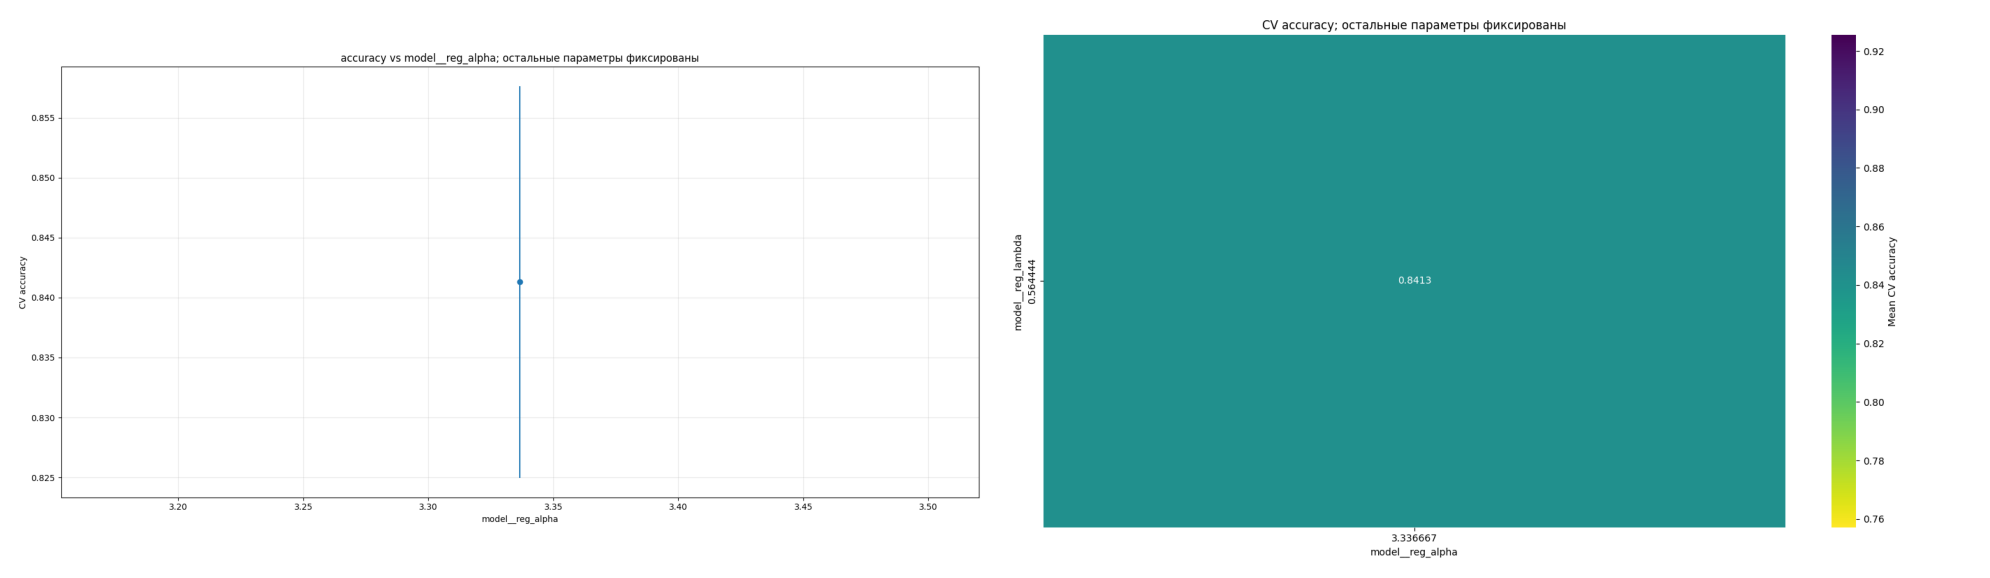

In [246]:
xgboost_results = run_experiment(
    X_train, y_train,
    "xgboost",
    xgboost_pipeline,
    logger
)
ModelSaver.save_ensemble(xgboost_results['best_ensemble'],"xgboost")

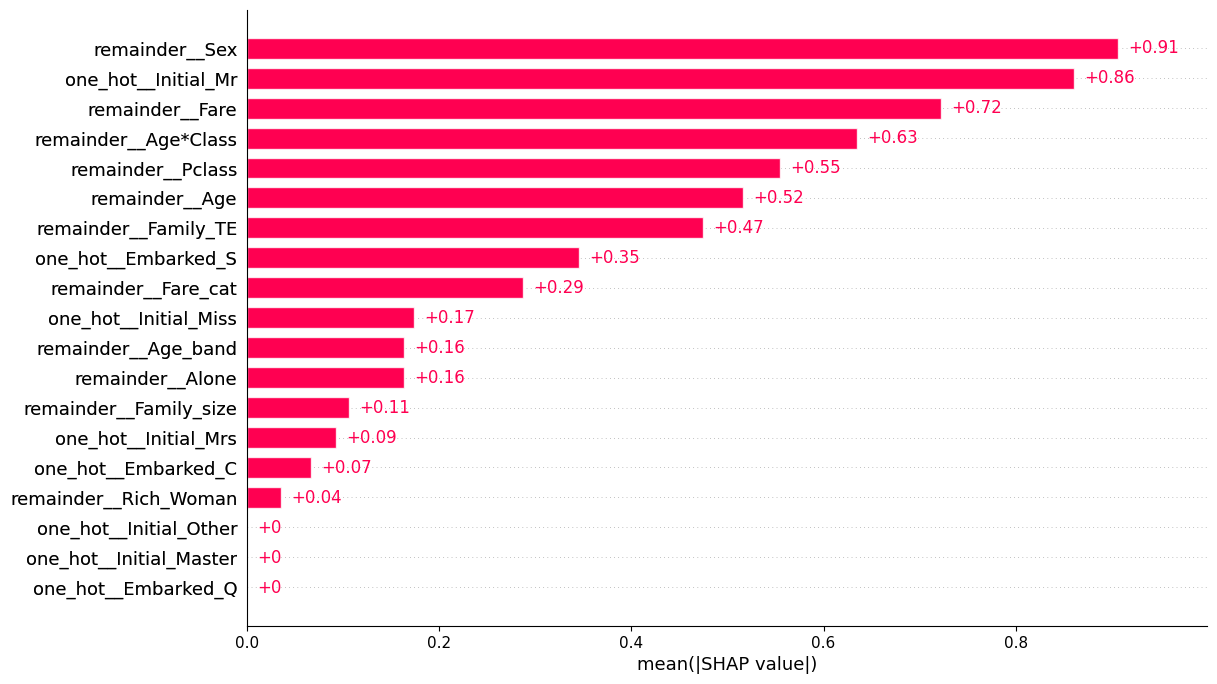

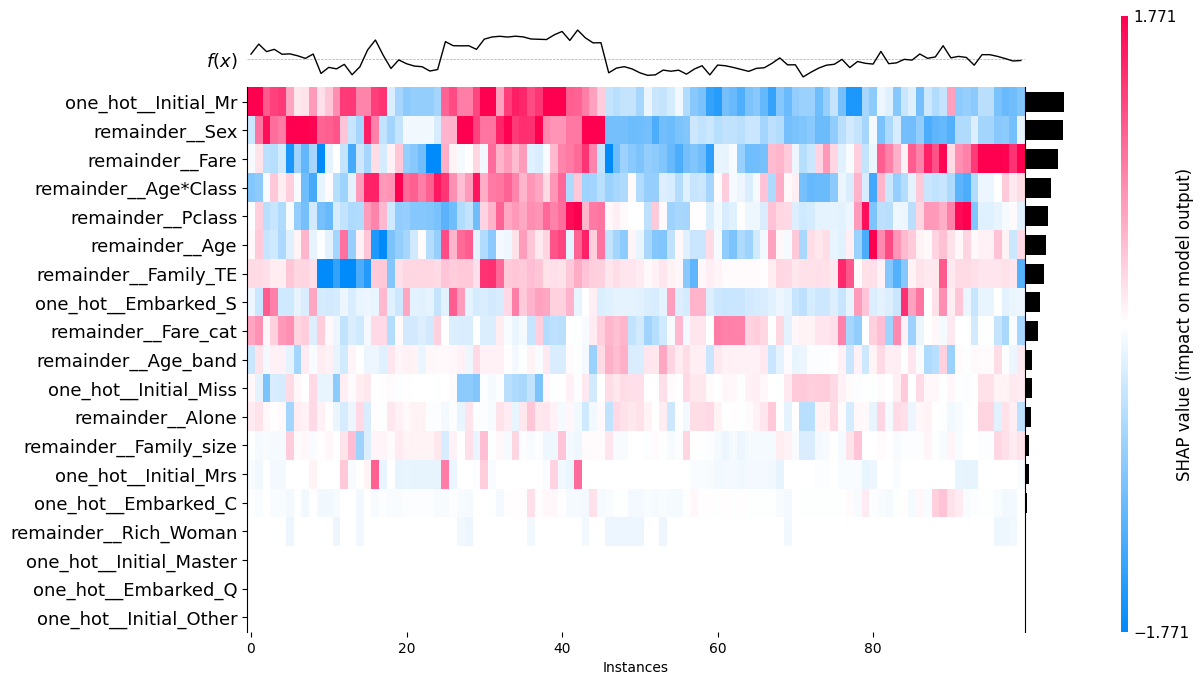

In [151]:
xgboost_shap = run_shap(
    X_train,
    xgboost_results,
    mode="xgboost",
    logger = logger
)

В случае с Xgboost инициалы тоже являются очень важной фичей, так же большее влияение у пола и цены билета, что в целом тоже логично и соответсвует исходным гипотезам

## Stacking LogReg

In [255]:
logreg_params = {
    "parameters": {
        "feature_transform__m": 4,
        "model__C": 1.053579,
        "model__penalty": "elasticnet",
        "model__solver": "saga",
        "model__max_iter": 2000,
        "model__l1_ratio": 0.7,
        "model__random_state": Config.seed,
        "model__n_jobs": -1,
    },
    "fit_param": {}
}

xgb_params = {
    "parameters": {
        "feature_transform__m": 1,
        "model__device": "cpu",
        "model__booster": "gbtree",
        "model__tree_method": "hist",
        "model__n_estimators": 300,
        "model__learning_rate": 0.9,
        "model__max_depth": 4,
        "model__min_child_weight": 5,
        "model__n_jobs": -1,
        "model__subsample": 0.6,
        "model__colsample_bytree": 0.8,
        "model__reg_alpha": 3.336667,
        "model__reg_lambda": 0.564444,
        "model__objective": "binary:logistic",
        "model__eval_metric": "error",
        "model__gamma": 0.1,
        "model__random_state": Config.seed,
    },
    "fit_param": {}
}

rf_params = {
    "parameters": {
        "feature_transform__m": 1,
        "model__n_estimators": 1000,
        "model__max_depth": 6,
        "model__criterion": "gini",
        "model__n_jobs": -1,
        "model__min_samples_split": 15,
        "model__min_samples_leaf": 15,
        "model__max_leaf_nodes": 12,
        "model__min_impurity_decrease": 0,
        "model__max_features": None,
        "model__bootstrap": True,
        "model__max_samples": 0.8,
        "model__oob_score": True,
        "model__random_state": Config.seed,
    },
    "fit_param": {}
}

lgbm_params = {
    "parameters": {
        "feature_transform__m": 1,
        "model__device": "cpu",
        "model__boosting_type": "gbdt",
        "model__n_estimators": 1000,
        "model__learning_rate": 0.1,
        "model__max_depth": 10,
        "model__min_child_weight": 1,
        "model__n_jobs": -1,
        "model__subsample": 0.6,
        "model__colsample_bytree": 0.8,
        "model__reg_alpha": 0.1,
        "model__reg_lambda": 10,
        "model__objective": "binary",
        "model__metric": "binary_error",
        "model__min_split_gain": 0.01,
        "model__random_state": Config.seed,
        "model__early_stopping_round": 30,
    },
    "fit_param": {}
}

cat_params = {
    "parameters": {
        "model__boosting_type": "Plain",
        "model__iterations": 1000,
        "model__learning_rate": 0.547368,
        "model__depth": 5,
        "model__bootstrap_type": "Bayesian",
        "model__thread_count": -1,
        "model__rsm": 1.0,
        "model__l2_leaf_reg": 3.164737,
        "model__eval_metric": "Accuracy",
        "model__border_count": 32,
        "model__loss_function": "Logloss",
        "model__random_seed": Config.seed,
        "model__bagging_temperature": 1,
        "model__random_strength": 0.5,
        "model__verbose": False,
        "model__early_stopping_rounds": 25,
    },
    "fit_param": {
        "model__cat_features": FeatureTransformer.X_cat_cols
    }
}

dnn_params = {
    "parameters": {
        "model__cat_cols": FeatureTransformer.X_cat_cols,
        "model__num_cols": FeatureTransformer.X_num_cols,

        # Обучение
        "model__epochs": 1000,
        "model__device": Config.device,

        # Архитектура
        "model__emb_dim": 24,
        "model__inner_n": 256,
        "model__drop_n": 0.1,
        "model__n_layers": 2,
        "model__use_batchnorm": True,

        # Loss
        "model__loss_cls": nn.CrossEntropyLoss,

        # Regularization
        "model__l1_lambda": 0.001,

        # Optimizer
        "model__optim": torch.optim.Adam,
        "model__optim_lr": 0.005,

        # Scheduler
        "model__scheduler": torch.optim.lr_scheduler.ReduceLROnPlateau,
        "model__lr_scheduler": True,
        "model__factor": 0.006,
        "model__patience": 15,
        "model__threshold": 0.05,
        "model__min_lr": 1e-15,

        # Early Stopping
        "model__early_stopping_patience": 25,
        "model__early_stopping_threshold": 0.001,

        # DataLoader
        "model__batch_size": 512,

        # Checkpoint
        "model__saving_threshold": 0.001,
        "model__save_path": "checkpoints",
    },
    "fit_param": {
        "model__callbacks": [
            CheckpointManager(),
            EarlyStopping()
        ],
    }
}

logreg_meta_params = {
    "parameters": {
        "model__C": 4,
        "model__penalty": "elasticnet",
        "model__solver": "saga",
        "model__max_iter": 2000,
        "model__l1_ratio": 0.5,
        "model__random_state": Config.seed,
        "model__n_jobs": -1,
    },
    "fit_param": {}
}
#------------------------------------------------------------------------------------------------------------------------------------
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=Config.seed)
cv_folds = list(kf.split(X_train, y_train))

meta_ridge = MyStackingRidge(groups = {"avg_boost": ["xgb", "catboost", "lightgbm"]},meta_cols=['avg_boost', "rf", "dnn", "logebase"]) #,'{"avg_boost": ["xgb", "catboost", "lightgbm"]} , ["xgb", "catboost", "lightgbm", "rf", "dnn", "ridgebase"]
meta_ridge.fit_sub_models(X_train, y_train,
        rf_params, dnn_params, cat_params,
        lgbm_params, xgb_params, logreg_params,
        cv_folds, Config.seed)

meta_res = meta_ridge.fit(X_train, y_train, logreg_meta_params, cv_folds, Config.seed)

print(f"Скор {meta_res['oof_accuracy']}\n")
ModelSaver.save_ensemble([meta_ridge],'meta_logreg')

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился xgb


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился catboost


Training:   0%|          | 0/5 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 218, number of negative: 351
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000290 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 286
[LightGBM] [Info] Number of data points in the train set: 569, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.383128 -> initscore=-0.476291
[LightGBM] [Info] Start training from score -0.476291
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 30 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

... (13 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился logebase


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Скор 0.8230337078651685



## Hold-out results

In [252]:
saved_models = ModelSaver.upload_saved_models(Config.path_to_save_models)


Model: catboost
Найдены модели
Selected features: all

Model: decision_tree
Найдены модели
Selected features: all

Model: dnn
Найдены модели
Selected features: all

Model: lightgbm
Найдены модели
Selected features: all

Model: logreg
Найдены модели
Selected features: all

Model: meta_logreg
Найдены модели
Selected features: all

Model: meta_ridge
Найдены модели
Selected features: all

Model: random_forest
Найдены модели
Selected features: all

Model: xgboost
Найдены модели
Selected features: all


In [253]:
Predictor.run_test(saved_models,X_holdout,y_holdout)
print()

        model  holdout_accuracy
          dnn           0.84916
   meta_ridge           0.84358
  meta_logreg           0.84358
      xgboost           0.83799
random_forest           0.83240
     catboost           0.82123
       logreg           0.82123
     lightgbm           0.81006
decision_tree           0.81006

